<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Run this first. Session verification</h2>

In [1]:
import subprocess
from datetime import datetime
import numpy as np

print("=" * 40)
print("SESSION VERIFICATION")
print("=" * 40)
print("Run time:", datetime.now())
print("Colab session ID:", subprocess.getoutput("hostname"))
print("=" * 40)

student_name = input("Enter your full name: ")
print("\nSubmitted by:", student_name)

SESSION VERIFICATION
Run time: 2026-11-23 14:12:10.896129
Colab session ID: wrds-sbd-07-w.wharton.private


Enter your full name:  Debasmita Halder



Submitted by: Debasmita Halder


<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Setup. Libraries and settings</h2>

In [2]:
# ===== Setup: libraries and settings =====
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # hide a harmless pandas warning

import pandas as pd
import wrds

conn = wrds.Connection()    # log in to WRDS (type your username and password if asked)

# Settings. If you want to change something, change it here only.
SIC        = "49"            # 2-digit industry we study (Transportation Equipment)
SIC_PEER        = "62"            # 2-digit industry we study (Transportation Equipment)
FY_START   = "2021-01-01"     #  Announcement Date
FY_END     = "2024-12-31"
PULL_START = "2019-01-01"     # we pull earlier years too, because the EPS change needs last year's EPS and price
RET_START  = "2020-12-01"     # first month of returns (12 months before the first fiscal year-end)
RET_END    = "2025-01-31"     # last month of returns
MIN_PRC    = 5                # rule: drop a company-year if last year's price is below this
MAX_CHG    = 1                # rule: drop a company-year if the EPS change is bigger than this (up or down)

Loading library list...
Done


<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Step 1. Link file (ccm_link.csv)</h2>

In [3]:
# ===== Step 1. Read the link file =====

# The code came from class notebook

# 1a. Read every column as text, so that nothing is changed or guessed at this point.
link_all = pd.read_csv("ccm_link.csv", dtype=str)

# 1b. gvkey must have 6 characters (for example 001690). Excel can drop the leading zeros, so we put them back.
link_all["gvkey"] = link_all["gvkey"].str.zfill(6)

# 1c. permno is a number.
link_all["permno"] = pd.to_numeric(link_all["permno"]).astype(int)

# 1d. The two date columns are text. Turn them into real dates, so that we can compare them with other dates.
# format="mixed" accepts different date formats. errors="coerce" turns a bad value into a missing date.
link_all["linkdt"]    = pd.to_datetime(link_all["linkdt"], format="mixed", errors="coerce")
link_all["linkenddt"] = pd.to_datetime(link_all["linkenddt"], format="mixed", errors="coerce")

# 1e. A link with no end date is still valid, so we give it a far-future end date.
link_all["linkenddt"] = link_all["linkenddt"].fillna(pd.Timestamp("2099-12-31"))

# 1f. Keep only the companies in our industry.
link = link_all[link_all["sic2"].isin([SIC, SIC_PEER])].reset_index(drop=True)
if len(link) == 0:
    raise ValueError("SIC " + SIC + " is not in ccm_link.csv. Industries in the file: " + str(sorted(link_all["sic2"].unique())))

print("link rows:", len(link), "| companies:", link["gvkey"].nunique())
link.head()


#link_all[link_all["ticker"] == "DUK"]

link rows: 269 | companies: 231


,gvkey,permno,linkdt,linkenddt,sic2,ticker,comnam
0,001075,27991,1962-01-31,2099-12-31,49,PNW,PINNACLE WEST CAPITAL CORP
1,001234,11587,1972-12-14,2024-08-30,49,ATRI,ATRION CORP
2,001439,12758,1984-05-09,2022-05-31,49,ECOL,U S ECOLOGY INC NEW
3,001440,24109,1951-01-01,1962-01-30,49,AEP,AMERICAN ELECTRIC POWER CO INC
4,001440,24109,1962-01-31,2099-12-31,49,AEP,AMERICAN ELECTRIC POWER CO INC


<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Step 2. Compustat quarter data (comp.fundq)</h2>

In [4]:
# ===== Step 2. Pull the quarter data =====

# The code came from class notebook

# 2a. The SQL query needs the gvkeys as one text:  '001690','002176',...
gv = "'" + "','".join(link["gvkey"].unique()) + "'"

# 2b. Ask WRDS for only the rows and columns we need.
fa = conn.raw_sql(f"""
    select gvkey, datadate, fyearq, epspxq, prccq,fqtr,CAST(fyearq AS TEXT) || CAST(fqtr AS TEXT) AS fyqr,rdq,
    fyearq * 4 + fqtr AS qnum
    from comp.fundq
    where gvkey in ({gv})
      and datadate between '{PULL_START}' and '{FY_END}'
      and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
""", date_cols=["datadate"])

# 2c. WRDS can return numbers in a special type. Turn them into plain decimal numbers (a missing value becomes NaN).
fa["epspxq"]  = fa["epspxq"].astype("float64")
fa["prccq"] = fa["prccq"].astype("float64")

# 2d. Check what we got.
print("company-years pulled from Compustat:", len(fa))
fa.head()

company-years pulled from Compustat: 4933


,gvkey,datadate,fyearq,epspxq,prccq,fqtr,fyqr,rdq,qnum
0,025042,2019-01-31,2019,NaN,NaN,1,20191,<NA>,8077
1,025911,2019-01-31,2019,NaN,NaN,1,20191,<NA>,8077
2,027849,2019-01-31,2019,NaN,NaN,1,20191,<NA>,8077
3,260737,2019-01-31,2018,-0.14,0.32,3,20183,2019-03-11,8075
4,006682,2019-02-28,2019,0.14,20.27,1,20191,2019-03-28,8077


<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Step 3. Add the link, then last year's values, then the EPS change</h2>

In [5]:
# ===== Step 3a. Merge 1: add permno from the link file =====

# The code came from class notebook

panel = fa.merge(link[["gvkey", "permno", "ticker", "linkdt", "linkenddt", "sic2"]], on="gvkey", how="inner")
print("3a. after the merge (a gvkey with 2 links is now on 2 rows):", len(panel))

#panel[
#    (panel["ticker"] == "DUK") &
#   (panel["datadate"] == "2019-06-30")]

3a. after the merge (a gvkey with 2 links is now on 2 rows): 5827


In [6]:
# ===== Step 3b. Keep only the link that was valid on the fiscal year-end date =====

# The code came from class notebook

# True/False for each row: the date is between the start and the end of the link.
valid = (panel["linkdt"] <= panel["datadate"]) & (panel["datadate"] <= panel["linkenddt"])
panel = panel[valid]

# How many rows share the same gvkey + fyear-quarter with another row?
n_dup = panel.duplicated(["gvkey", "fyqr"]).sum()
print("3b. rows that repeat a gvkey +fyqr before we drop them:", n_dup)

#add code
duplicates = panel[panel.duplicated(["gvkey", "fyqr"], keep=False)]

print(duplicates[["gvkey", "fyqr", "sic2", "permno"]])



# If one company-year-quarter still has two rows, keep one.
panel = panel.drop_duplicates(["gvkey", "fyqr"])

# We do not need the link dates any more.
panel = panel.drop(columns=["linkdt", "linkenddt"]).reset_index(drop=True)

# Count (used in the sample construction table in Step 6).
#r1, c1 = len(fa), fa["gvkey"].nunique()          # before the link
#r2, c2 = len(panel), panel["gvkey"].nunique()    # after the link

# SIC 49
fa49 = fa[fa["gvkey"].isin(link.loc[link["sic2"] == "49", "gvkey"])]

r1, c1 = len(fa49), fa49["gvkey"].nunique()
r2, c2 = len(panel[panel["sic2"] == "49"]), panel.loc[panel["sic2"] == "49", "gvkey"].nunique()

# SIC 62 (Peer)
fa62 = fa[fa["gvkey"].isin(link.loc[link["sic2"] == "62", "gvkey"])]

r1_peer, c1_peer = len(fa62), fa62["gvkey"].nunique()
r2_peer, c2_peer = len(panel[panel["sic2"] == "62"]), panel.loc[panel["sic2"] == "62", "gvkey"].nunique()



#print("3b. company-years after the link merge:", r2)

print("3b. Company-quarters before the link merge -49:", r1)
print("3b. Company-quarters after valid link dates:-49", r2)
print("3b. Company-quarters before the link merge -62:", r1_peer)
print("3b. Company-quarters after valid link dates:-62", r2_peer)


3b. rows that repeat a gvkey +fyqr before we drop them: 3
       gvkey   fyqr sic2  permno
3255  266257  20221   62   90121
3500  266257  20221   62   90121
3501  266257  20222   62   90121
3743  266257  20222   62   90121
3744  266257  20223   62   90121
3982  266257  20223   62   90121
3b. Company-quarters before the link merge -49: 2838
3b. Company-quarters after valid link dates:-49 2726
3b. Company-quarters before the link merge -62: 2095
3b. Company-quarters after valid link dates:-62 2053


In [7]:
# ===== Check: does any key (gvkey + fyqr) appear more than once? =====
# The code came from class notebook

# duplicated() marks a row True if an earlier row has the same gvkey and fyear-quarter. sum() counts the True values.
print("duplicate keys:", panel.duplicated(["gvkey", "fyqr"]).sum(), "(it must be 0)")

duplicate keys: 0 (it must be 0)


In [8]:
# ===== Step 3c. Merge 2: add last year's EPS =====

# The code came from class notebook and the quarter logic is my own 

# Make a copy with only the columns we need.
last = panel[["gvkey", "qnum", "epspxq"]].copy()

# Move every year forward by one: the values of 2021 are now on the row of 2022.

last["qnum"] = last["qnum"]+4



# Give the columns new names, so that this year's and last year's values do not mix.
last = last.rename(columns={"epspxq": "epsq_lag1"})


print("Before merge2 with last year:", len(panel))

# Merge. how="left": keep every row of panel, even when there is no last year.
panel = panel.merge(last, on=["gvkey", "qnum"], how="left")

print("After merge2 with last year:", len(panel))


last.head(6)



Before merge2 with last year: 4779
After merge2 with last year: 4779


,gvkey,qnum,epsq_lag1
0,025042,8081,NaN
1,025911,8081,NaN
2,027849,8081,NaN
3,260737,8079,-0.14
4,006682,8081,0.14
5,148435,8082,NaN


In [9]:
# step : 3d calculate last quater price 

# The code came from class notebook and the quarter logic is my own 


# Make a copy with only the columns we need.

lastprice = panel[["gvkey", "qnum", "prccq"]].copy()


lastprice["qnum"] = lastprice["qnum"]+1


# Give the columns new names, so that this year's and last year's values do not mix.
lastprice = lastprice.rename(columns={ "prccq": "prcq_lag1"})


print("Before price merge:", len(panel))


# Merge. how="left": keep every row of panel, even when there is no last year.
panel = panel.merge(lastprice, on=["gvkey", "qnum"], how="left")

print("After price merge:", len(panel))

# Save counts
# SIC 49
r3, c3 = len(panel[panel["sic2"] == "49"]), panel.loc[panel["sic2"] == "49", "gvkey"].nunique()

# SIC 62 (Peer)
r3_peer, c3_peer = len(panel[panel["sic2"] == "62"]), panel.loc[panel["sic2"] == "62", "gvkey"].nunique()


# The EPS change: (this year's EPS - last year's EPS) / last year's price.
panel["eps_chg"] = (panel["epspxq"] - panel["epsq_lag1"]) / panel["prcq_lag1"]

panel[["gvkey", "fyearq","fyqr", "epspxq", "epsq_lag1", "prcq_lag1", "eps_chg","rdq"]].head(8)

Before price merge: 4779
After price merge: 4779


,gvkey,fyearq,fyqr,epspxq,epsq_lag1,prcq_lag1,eps_chg,rdq
0,025042,2019,20191,NaN,NaN,NaN,NaN,<NA>
1,025911,2019,20191,NaN,NaN,NaN,NaN,<NA>
2,027849,2019,20191,NaN,NaN,NaN,NaN,<NA>
3,260737,2018,20183,-0.14,NaN,NaN,NaN,2019-03-11
4,006682,2019,20191,0.14,NaN,NaN,NaN,2019-03-28
5,148435,2019,20192,NaN,NaN,NaN,NaN,<NA>
6,152029,2019,20191,NaN,NaN,NaN,NaN,<NA>
7,155324,2018,20184,NaN,NaN,NaN,NaN,<NA>


In [10]:
######## validation###############

# ===== Step 3e. Apply screening rules =====

# The code came from class notebook


# Rule 1: Announcement date is known

# SIC 49
print("Rule 1 - SIC 49 Before:", len(panel[panel["sic2"] == SIC]))

events = panel[(panel["sic2"] == SIC) & (panel["rdq"].notna())].copy()

print("Rule 1 - SIC 49 After:", len(events))

r4, c4 = len(events), events["gvkey"].nunique()

# SIC 62
print("Rule 1 - SIC 62 Before:", len(panel[panel["sic2"] == SIC_PEER]))

events_peer = panel[(panel["sic2"] == SIC_PEER) & (panel["rdq"].notna())].copy()

print("Rule 1 - SIC 62 After:", len(events_peer))

r4_peer, c4_peer = len(events_peer), events_peer["gvkey"].nunique()


# Rule 2: Sample period

# SIC 49
events = events[
    (events["rdq"] >= FY_START) &
    (events["rdq"] <= FY_END)
].copy()

r5, c5 = len(events), events["gvkey"].nunique()
print("Rule 2 - SIC 49 Sample period:", len(events))

# SIC 62
events_peer = events_peer[
    (events_peer["rdq"] >= FY_START) &
    (events_peer["rdq"] <= FY_END)
].copy()

r5_peer, c5_peer = len(events_peer), events_peer["gvkey"].nunique()
print("Rule 2 - SIC 62 Sample period:", len(events_peer))


# Rule 3: SUE can be computed

# SIC 49
events = events[events["eps_chg"].notna()].copy()
print("Rule 3 - SIC 49 SUE available:", len(events))

events = events.reset_index(drop=True)

r6, c6 = len(events), events["gvkey"].nunique()

# SIC 62
events_peer = events_peer[events_peer["eps_chg"].notna()].copy()
print("Rule 3 - SIC 62 SUE available:", len(events_peer))

events_peer = events_peer.reset_index(drop=True)

r6_peer, c6_peer = len(events_peer), events_peer["gvkey"].nunique()


# Rule 4: Last quarter price >= $5

# SIC 49
print("Rule 4 - SIC 49 Before:", len(events))

events = events[events["prcq_lag1"] >= MIN_PRC].copy()

r7, c7 = len(events), events["gvkey"].nunique()

print("Rule 4 - SIC 49 After:", len(events))

# SIC 62
print("Rule 4 - SIC 62 Before:", len(events_peer))

events_peer = events_peer[events_peer["prcq_lag1"] >= MIN_PRC].copy()

r7_peer, c7_peer = len(events_peer), events_peer["gvkey"].nunique()

print("Rule 4 - SIC 62 After:", len(events_peer))


# Rule 5: Absolute SUE <= MAX_CHG

# SIC 49
events = events[events["eps_chg"].abs() <= MAX_CHG].copy()

r8, c8 = len(events), events["gvkey"].nunique()

print("Rule 5 - SIC 49 After:", len(events))

# SIC 62
events_peer = events_peer[events_peer["eps_chg"].abs() <= MAX_CHG].copy()

r8_peer, c8_peer = len(events_peer), events_peer["gvkey"].nunique()

print("Rule 5 - SIC 62 After:", len(events_peer))

#creating the tables for calculating 5 days car

events_abn=events.copy()
events_peer_abn=events_peer.copy()

Rule 1 - SIC 49 Before: 2726
Rule 1 - SIC 49 After: 2697
Rule 1 - SIC 62 Before: 2053
Rule 1 - SIC 62 After: 1614
Rule 2 - SIC 49 Sample period: 1788
Rule 2 - SIC 62 Sample period: 1069
Rule 3 - SIC 49 SUE available: 1734
Rule 3 - SIC 62 SUE available: 1037
Rule 4 - SIC 49 Before: 1734
Rule 4 - SIC 49 After: 1619
Rule 4 - SIC 62 Before: 1037
Rule 4 - SIC 62 After: 954
Rule 5 - SIC 49 After: 1618
Rule 5 - SIC 62 After: 953


<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Step 4. Daily stock and market returns (crsp.msf, crsp.msi)</h2>

In [11]:
# ===== Step 4. Pull the returns and compute the daily abnormal return =====

# The code came from class notebook


# 4a. The stocks we need: the permnos of the company-years in `events`.
permnos = ",".join(events["permno"].astype(str).unique())

# 4b. Ask WRDS for the daily stock returns and the daily market returns.
stock = conn.raw_sql(f"""select permno, date, ret from crsp.dsf
                         where permno in ({permnos}) and date between '{RET_START}' and '{RET_END}'""",
                     date_cols=["date"])
mkt = conn.raw_sql(f"""select date, vwretd from crsp.dsi
                       where date between '{RET_START}' and '{RET_END}'""",
                   date_cols=["date"])

# 4c. Plain numbers (a missing return becomes NaN).
stock["permno"] = stock["permno"].astype(int)
stock["ret"]    = stock["ret"].astype("float64")
mkt["vwretd"]   = mkt["vwretd"].astype("float64")

# 4d. Give each market trading day a number
mkt = mkt.sort_values("date").reset_index(drop=True)

mkt["tday"] = mkt.index + 1

# 4e. Merge 3: add the market return of the same month to every stock-month.
stock = stock.merge(mkt[["date", "vwretd","tday"]], on="date", how="left")

# 4f. Abnormal return = stock return - market return.
stock["ar"] = stock["ret"] - stock["vwretd"]

print("stock-days:", len(stock), "| day with a missing return:", int(stock["ar"].isna().sum()))
stock.head()


# ===== Step 4. Daily abnormal returns for SIC 62 =====

# 4a. Get peer company PERMNOs
permnos_peer = ",".join(events_peer["permno"].astype(str).unique())

# 4b. Pull peer daily stock returns
stock_peer = conn.raw_sql(f"""
    select permno, date, ret
    from crsp.dsf
    where permno in ({permnos_peer})
    and date between '{RET_START}' and '{RET_END}'
""", date_cols=["date"])

# 4c. Convert to numeric types
stock_peer["permno"] = stock_peer["permno"].astype(int)
stock_peer["ret"] = stock_peer["ret"].astype("float64")

# 4d. Merge with the existing market trading days
stock_peer = stock_peer.merge(
    mkt[["date", "vwretd", "tday"]],
    on="date",
    how="left"
)

# 4e. Calculate peer abnormal returns
stock_peer["ar"] = stock_peer["ret"] - stock_peer["vwretd"]

print("Peer stock-days:", len(stock_peer))
print("Peer missing abnormal returns:", stock_peer["ar"].isna().sum())

stock_peer.head()

stock-days: 110486 | day with a missing return: 5
Peer stock-days: 63300
Peer missing abnormal returns: 78


,permno,date,ret,vwretd,tday,ar
0,10138,2020-12-01,0.014574,0.009645,1,0.004929
1,10138,2020-12-02,0.006942,0.001192,2,0.005750
2,10138,2020-12-03,0.024299,0.002272,3,0.022027
3,10138,2020-12-04,0.016392,0.010477,4,0.005915
4,10138,2020-12-07,-0.008064,-0.000220,5,-0.007844


<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Step 5. The 3days 
abnormal return of each company-quarter</h2>

In [12]:
# ===== Step 5. Calculate 3-day cumulative abnormal returns (CAR) =====

# The code came from class notebook 


# 5a. Give every company-quarter a unique event_id

events = events.reset_index(drop=True) 
events["event_id"] = events.index

print("Before Merge pair:", len(events))

# 5b. Merge 4: put every company-year next to ALL the months of its stock.
pairs = events[["event_id", "rdq"]].merge(
    mkt[["date", "tday"]],
    how="cross"
)

print("After Merge pair:", len(pairs))

#5c. covert sting to datetime
pairs["rdq"] = pd.to_datetime(pairs["rdq"])
#pairs["date"] = pd.to_datetime(pairs["date"])

#keep the date where it's greater than announcement date

pairs = pairs[pairs["date"] >= pairs["rdq"]]

# 5d. Find the first trading day for each earnings announcement
day0 = pairs.groupby("event_id")["tday"].min().reset_index()

# Rename tday to day0
day0 = day0.rename(columns={"tday": "day0"})

# Add day0 to events
events = events.merge(
    day0,
    on="event_id",
    how="left"
)

print(events[["event_id", "rdq", "day0"]].head())

# 5e. Create Day -1, Day 0, and Day +1
offsets = pd.DataFrame({"offset_days": [-1, 0, 1]})

window = events[["event_id", "permno", "rdq", "day0"]].merge(
    offsets,
    how="cross"
)

# Calculate trading-day numbers
window["tday"] = window["day0"] + window["offset_days"]

print("Three-day window rows:", len(window))


# 5f. Match the three trading days with abnormal stock returns
window = window.merge(
    stock[["permno", "tday", "ar"]],
    on=["permno", "tday"],
    how="left",
    validate="many_to_one"
)

print("After stock return merge:", len(window))


# 5g. Sum abnormal returns and count available days
abn = window.groupby("event_id")["ar"].agg(
    ["sum", "count"]
).reset_index()

abn = abn.rename(columns={
    "sum": "car",
    "count": "days_found"
})


# 5h. Add CAR back to quarterly earnings events
print("Before adding CAR Merge:", len(events))

events = events.merge(
    abn,
    on="event_id",
    how="left",
    validate="one_to_one"
)

print("After adding CAR Merge:", len(events))


# Count available abnormal returns
events["days_found"] = events["days_found"].fillna(0).astype(int)

print("How many of the 3 trading days were found:")
print(events["days_found"].value_counts().sort_index())


# 5i. Check one earnings announcement
print(window[["event_id", "rdq", "offset_days", "tday", "ar"]].head(9))

#count after merging CAR data

r9, c9 = len(events), events["gvkey"].nunique()


####################### add for peer##################################

# ===== Step 5. Calculate 3-day cumulative abnormal returns (CAR) =====

# The code came from class notebook 


# 5a. Give every company-quarter a unique event_id

events_peer = events_peer.reset_index(drop=True) 
events_peer["event_id"] = events_peer.index

print("Before Merge pair:", len(events_peer))

# 5b. Merge 4: put every company-year next to ALL the months of its stock.
pairs_peer = events_peer[["event_id", "rdq"]].merge(
    mkt[["date", "tday"]],
    how="cross"
)

print("After Merge pair:", len(pairs_peer))

#5c. covert sting to datetime
pairs_peer["rdq"] = pd.to_datetime(pairs_peer["rdq"])
#pairs["date"] = pd.to_datetime(pairs["date"])

#keep the date where it's greater than announcement date

pairs_peer = pairs_peer[pairs_peer["date"] >= pairs_peer["rdq"]]

# 5d. Find the first trading day for each earnings announcement
day0_peer = pairs_peer.groupby("event_id")["tday"].min().reset_index()

# Rename tday to day0
day0_peer = day0_peer.rename(columns={"tday": "day0"})

# Add day0 to events
events_peer = events_peer.merge(
    day0_peer,
    on="event_id",
    how="left"
)

print(events_peer[["event_id", "rdq", "day0"]].head())

# 5e. Create Day -1, Day 0, and Day +1
offsets_peer = pd.DataFrame({"offset_days": [-1, 0, 1]})

window_peer = events_peer[["event_id", "permno", "rdq", "day0"]].merge(
    offsets_peer,
    how="cross"
)

# Calculate trading-day numbers
window_peer["tday"] = window_peer["day0"] + window_peer["offset_days"]

print("Three-day window rows:", len(window_peer))


# 5f. Match the three trading days with abnormal stock returns
window_peer = window_peer.merge(
    stock_peer[["permno", "tday", "ar"]],
    on=["permno", "tday"],
    how="left",
    validate="many_to_one"
)

print("After stock return merge:", len(window_peer))


# 5g. Sum abnormal returns and count available days
abn_peer = window_peer.groupby("event_id")["ar"].agg(
    ["sum", "count"]
).reset_index()

abn_peer = abn_peer.rename(columns={
    "sum": "car",
    "count": "days_found"
})


# 5h. Add CAR back to quarterly earnings events
print("Before adding CAR Merge:", len(events_peer))

events_peer = events_peer.merge(
    abn_peer,
    on="event_id",
    how="left",
    validate="one_to_one"
)

print("After adding CAR Merge:", len(events_peer))


# Count available abnormal returns
events_peer["days_found"] = events_peer["days_found"].fillna(0).astype(int)

print("How many of the 3 trading days were found:")
print(events_peer["days_found"].value_counts().sort_index())


# 5i. Check one earnings announcement
print(window_peer[["event_id", "rdq", "offset_days", "tday", "ar"]].head(9))

#count after merging CAR data

r9_peer, c9_peer = len(events_peer), events_peer["gvkey"].nunique()







Before Merge pair: 1618
After Merge pair: 1661686
   event_id         rdq  day0
0         0  2021-02-24    58
1         1  2021-02-26    60
2         2  2021-02-25    59
3         3  2021-02-25    59
4         4  2021-02-09    48
Three-day window rows: 4854
After stock return merge: 4854
Before adding CAR Merge: 1618
After adding CAR Merge: 1618
How many of the 3 trading days were found:
days_found
0       5
2       3
3    1610
Name: count, dtype: int64
   event_id         rdq  offset_days  tday        ar
0         0  2021-02-24           -1    57  0.013482
1         0  2021-02-24            0    58 -0.043616
2         0  2021-02-24            1    59  0.026335
3         1  2021-02-26           -1    59  0.001030
4         1  2021-02-26            0    60 -0.019748
5         1  2021-02-26            1    61 -0.002505
6         2  2021-02-25           -1    58  0.023568
7         2  2021-02-25            0    59 -0.013918
8         2  2021-02-25            1    60 -0.023889
Before Merge

<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Step 6. The rules and the sample construction table</h2>

In [13]:
# ===== Step 6a. Rule 1: all 3 trading days have a return =====

# The code came from class notebook

events = events[events["days_found"] == 3]
r10, c10= len(events), events["gvkey"].nunique()

events_peer = events_peer[events_peer["days_found"] == 3]
r10_peer, c10_peer= len(events_peer), events_peer["gvkey"].nunique()

print("company-years left:", r10)

print("company-years left:", r10_peer)

company-years left: 1610
company-years left: 936


In [14]:

display(events.head())
display(events_peer.head())

,gvkey,datadate,fyearq,epspxq,prccq,fqtr,fyqr,rdq,qnum,permno,ticker,sic2,epsq_lag1,prcq_lag1,eps_chg,event_id,day0,car,days_found
0,001075,2020-12-31,2020,-0.17,79.95,4,20204,2021-02-24,8084,27991,PNW,49,0.57,74.55,-0.009926,0,58,-0.003799,3
1,001234,2020-12-31,2020,4.03,642.24,4,20204,2021-02-26,8084,11587,ATRI,49,4.35,626.00,-0.000511,1,60,-0.021223,3
2,001439,2020-12-31,2020,-2.97,36.33,4,20204,2021-02-25,8084,12758,ECOL,49,-0.12,32.67,-0.087236,2,59,-0.014239,3
3,001440,2020-12-31,2020,0.87,83.27,4,20204,2021-02-25,8084,24109,AEP,49,0.31,81.73,0.006852,3,59,-0.022901,3
4,002259,2020-12-31,2020,1.23,61.45,4,20204,2021-02-09,8084,61946,BKH,49,1.13,53.49,0.001870,4,48,-0.009503,3


,gvkey,datadate,fyearq,epspxq,prccq,fqtr,fyqr,rdq,qnum,permno,ticker,sic2,epsq_lag1,prcq_lag1,eps_chg,event_id,day0,car,days_found
0,006682,2020-11-30,2020,1.12,22.73,4,20204,2021-01-04,8084,20415,JEF,62,0.63,17.54,0.027936,0,23,0.033788,3
1,176999,2020-11-30,2020,0.57,22.13,3,20203,2021-01-06,8083,91858,SAR,62,1.37,17.14,-0.046674,1,25,0.080067,3
2,002369,2020-12-31,2020,0.41,41.27,4,20204,2021-02-11,8084,85259,BN,62,0.76,33.06,-0.010587,2,50,0.031045,3
3,004885,2020-12-31,2021,0.67,24.99,1,20211,2021-02-02,8085,37584,BEN,62,0.70,20.35,-0.001474,3,43,-0.048338,3
4,007163,2020-12-31,2020,1.89,328.73,4,20204,2021-02-09,8084,17478,SPGI,62,2.22,360.60,-0.000915,4,48,0.017140,3


In [15]:
# ===== Step 6b. Look at the extreme EPS changes (before rules 2 and 3) =====

# The code came from class notebook
# Columns to show.
show = ["ticker", "datadate", "epspxq", "epsq_lag1", "prcq_lag1", "eps_chg"]

# Sort from the smallest to the largest EPS change. head(5) = first 5 rows, tail(5) = last 5 rows.
print("5 smallest EPS changes:")
print(events.sort_values("eps_chg")[show].head(5).to_string(index=False))
print()
print("5 largest EPS changes:")
print(events.sort_values("eps_chg")[show].tail(5).to_string(index=False))
print()
events["eps_chg"].describe()


#peer

show1 = ["ticker", "datadate", "epspxq", "epsq_lag1", "prcq_lag1", "eps_chg"]

# Sort from the smallest to the largest EPS change. head(5) = first 5 rows, tail(5) = last 5 rows.
print("5 smallest EPS changes:")
print(events_peer.sort_values("eps_chg")[show1].head(5).to_string(index=False))
print()
print("5 largest EPS changes:")
print(events_peer.sort_values("eps_chg")[show1].tail(5).to_string(index=False))
print()
events_peer["eps_chg"].describe()


5 smallest EPS changes:
ticker   datadate  epspxq  epsq_lag1  prcq_lag1   eps_chg
   SMC 2021-12-31   -3.42      30.45      35.55 -0.952743
   KEP 2022-12-31   -6.10      -2.39       6.80 -0.545588
   SMC 2024-09-30  -19.25      -0.27      35.56 -0.533746
   NRG 2020-12-31   -0.70      13.79      30.74 -0.471373
   SMC 2022-06-30   -9.53      -2.91      14.88 -0.444892

5 largest EPS changes:
ticker   datadate  epspxq  epsq_lag1  prcq_lag1  eps_chg
  USAC 2021-03-31   -0.12      -6.36      13.60 0.458824
   SMC 2023-06-30   -1.91      -9.53      15.35 0.496417
  ETRN 2022-12-31    0.15      -3.68       7.48 0.512032
   PCG 2020-12-31    0.11      -6.85       9.39 0.741214
   SMC 2024-03-31   12.05      -1.82      17.91 0.774428

5 smallest EPS changes:
ticker   datadate  epspxq  epsq_lag1  prcq_lag1   eps_chg
  COHN 2022-03-31   -5.46       9.04    14.8100 -0.979068
  AAMC 2022-09-30   -2.24       5.06    10.2489 -0.712272
  COHN 2022-12-31   -2.10       3.13     8.5100 -0.614571
  COH

count    936.000000
mean       0.003330
std        0.090683
min       -0.979068
25%       -0.006504
50%        0.001507
75%        0.008426
max        0.780675
Name: eps_chg, dtype: float64

In [16]:
# ===== Step 6e. The sample construction tables =====
# The code came from class notebook

# SIC 49
sample_table = pd.DataFrame({
    "step": ["1. Compustat quarter data, SIC " + SIC + " (fundq)",
             "2. after the link merge (with the link dates)",
             "3. EPS change can be computed (merge with last quarter)",
             "4. Announcement date is known",
             "5. earnings announcements in the sample period",
             "6. SUE Available",
             "7. previous quarter's price >= $" + str(MIN_PRC),
             "8. |EPS change| <= " + str(MAX_CHG),
             "9.Merge with CAR data:",
             "10.All 3 trading days found"],
    "rows left": [r1, r2, r3, r4, r5, r6, r7, r8, r9, r10],
    "companies left": [c1, c2, c3, c4, c5, c6, c7, c8, c9, c10],
})

sample_table["rows removed"] = -sample_table["rows left"].diff()
sample_table["rows removed"] = sample_table["rows removed"].fillna(0).astype(int)

print("SIC 49 - Sample Construction Table")
display(sample_table)


# SIC 62
sample_table_peer = pd.DataFrame({
    "step": ["1. Compustat quarter data, SIC " + SIC_PEER + " (fundq)",
             "2. after the link merge (with the link dates)",
             "3. EPS change can be computed (merge with last quarter)",
             "4. Announcement date is known",
             "5. earnings announcements in the sample period",
             "6. SUE Available",
             "7. previous quarter's price >= $" + str(MIN_PRC),
             "8. |EPS change| <= " + str(MAX_CHG),
             "9.Merge with CAR data:",
             "10.All 3 trading days found"],
    "rows left": [r1_peer, r2_peer, r3_peer, r4_peer, r5_peer,
                  r6_peer, r7_peer, r8_peer, r9_peer, r10_peer],
    "companies left": [c1_peer, c2_peer, c3_peer, c4_peer, c5_peer,
                       c6_peer, c7_peer, c8_peer, c9_peer, c10_peer],
})

sample_table_peer["rows removed"] = -sample_table_peer["rows left"].diff()
sample_table_peer["rows removed"] = sample_table_peer["rows removed"].fillna(0).astype(int)

print("SIC 62 - Sample Construction Table")
display(sample_table_peer)

SIC 49 - Sample Construction Table


,step,rows left,companies left,rows removed
0,"1. Compustat quarter data, SIC 49 (fundq)",2838,127,0
1,2. after the link merge (with the link dates),2726,126,112
2,3. EPS change can be computed (merge with last...,2726,126,0
3,4. Announcement date is known,2697,126,29
4,5. earnings announcements in the sample period,1788,126,909
5,6. SUE Available,1734,123,54
6,7. previous quarter's price >= $5,1619,118,115
7,8. |EPS change| <= 1,1618,118,1
8,9.Merge with CAR data:,1618,118,0
9,10.All 3 trading days found,1610,118,8


SIC 62 - Sample Construction Table


,step,rows left,companies left,rows removed
0,"1. Compustat quarter data, SIC 62 (fundq)",2095,95,0
1,2. after the link merge (with the link dates),2053,95,42
2,3. EPS change can be computed (merge with last...,2053,95,0
3,4. Announcement date is known,1614,76,439
4,5. earnings announcements in the sample period,1069,76,545
5,6. SUE Available,1037,75,32
6,7. previous quarter's price >= $5,954,67,83
7,8. |EPS change| <= 1,953,67,1
8,9.Merge with CAR data:,953,67,0
9,10.All 3 trading days found,936,67,17


In [17]:
# ===== Step 6f. The final table: summary of the two main variables =====
print("Final table: one row =", "one company and one fiscal quarter")
events[["eps_chg", "car"]].describe()

Final table: one row = one company and one fiscal quarter


,eps_chg,car
count,1610.000000,1610.000000
mean,0.002090,0.002294
std,0.069133,0.050402
min,-0.952743,-0.381414
25%,-0.002868,-0.021240
50%,0.000703,0.001491
75%,0.004686,0.025478
max,0.774428,0.374529


In [18]:
# ===== Step 6f. The final table: summary of the two main variables =====
print("Final table: one row =", "one company and one fiscal quarter")
events_peer[["eps_chg", "car"]].describe()

Final table: one row = one company and one fiscal quarter


,eps_chg,car
count,936.000000,936.000000
mean,0.003330,0.007140
std,0.090683,0.075310
min,-0.979068,-0.760934
25%,-0.006504,-0.025948
50%,0.001507,0.004609
75%,0.008426,0.035225
max,0.780675,1.160469


In [19]:
print("Total observations:", len(events))

print("Duplicate company-quarters:",
      events.duplicated(["gvkey", "fyqr"]).sum())

Total observations: 1610
Duplicate company-quarters: 0


In [20]:
# ===== Check 3(a): Announcement date after quarter end =====


events["rdq"] = pd.to_datetime(events["rdq"])
events["datadate"] = pd.to_datetime(events["datadate"])

print("Announcement date Early:",
      (events["rdq"] <=events["datadate"]).sum())


#  Day 0 is a trading day =====


print("Day 0 dates are valid:",
      events["day0"].isin(mkt["tday"]).all())

Announcement date Early: 0
Day 0 dates are valid: True


In [21]:
# 5 largest CARs .
show = ["ticker", "datadate", "fyqr", "rdq", "car", "days_found"]

top5 = events.loc[events["car"].abs().nlargest(5).index]
print(top5[show].to_string(index=False))

ticker   datadate  fyqr        rdq       car  days_found
   SMC 2021-12-31 20214 2022-02-25 -0.381414           3
   SJI 2021-12-31 20214 2022-02-24  0.374529           3
   AQN 2022-09-30 20223 2022-11-11 -0.337308           3
  NOVA 2022-06-30 20222 2022-07-27  0.275889           3
  CWCO 2022-09-30 20223 2022-11-14 -0.274051           3


In [22]:

show = ["ticker", "fyqr", "datadate", "rdq",
        "epspxq", "epsq_lag1", "prccq", "prcq_lag1","eps_chg"]

print(events[
    (events["ticker"] == "DUK") &
    (events["fyqr"] == 20241)
][show].to_string(index=False))

#---- price in last quarter ago------

show = ["ticker", "fyqr", "datadate",  "prccq"]

print(events[
    (events["ticker"] == "DUK") &
    (events["fyqr"] == 20234)
][show].to_string(index=False))

#---- Eps in last 4 qyuarter ago------

show = ["ticker", "fyqr", "datadate", "rdq",
        "epspxq"]

print(events[
    (events["ticker"] == "DUK") &
    (events["fyqr"] == 20231)
][show].to_string(index=False))

Empty DataFrame
Columns: [ticker, fyqr, datadate, rdq, epspxq, epsq_lag1, prccq, prcq_lag1, eps_chg]
Index: []
Empty DataFrame
Columns: [ticker, fyqr, datadate, prccq]
Index: []
Empty DataFrame
Columns: [ticker, fyqr, datadate, rdq, epspxq]
Index: []


In [23]:
# Duke Energy 2024 Q1
show = ["ticker", "fyqr", "datadate", "rdq", "permno", "car"]

print(events[
    (events["ticker"] == "DUK") &
    (events["fyqr"] == 20241)
][show].to_string(index=False))

# Day 0 and Day 1 for Announment day : May 7,2024
display(stock[
    (stock["permno"] == 27959) &
    (stock["date"] >= "2024-05-07")
][["permno", "date", "ret", "vwretd", "ar"]].head(3))

# day -1 Before May 7,2024
display(stock[
    (stock["permno"] == 27959) &
    (stock["date"] < "2024-05-07")
][["permno", "date", "ret", "vwretd", "ar"]].tail(2))

Empty DataFrame
Columns: [ticker, fyqr, datadate, rdq, permno, car]
Index: []


,permno,date,ret,vwretd,ar
60552,27959,2024-05-07,0.018323,0.000938,0.017385
60553,27959,2024-05-08,0.001173,-0.001021,0.002194
60554,27959,2024-05-09,0.006251,0.005880,0.000371


,permno,date,ret,vwretd,ar
60550,27959,2024-05-03,0.009566,0.011428,-0.001862
60551,27959,2024-05-06,0.001596,0.010648,-0.009052


In [24]:
# High, Middle and Low SUE groups

# SIC 49
events["sue_group"] = pd.qcut(
    events["eps_chg"].rank(method="first"),
    3,
    labels=["Low", "Middle", "High"]
)

# SIC 62
events_peer["sue_group"] = pd.qcut(
    events_peer["eps_chg"].rank(method="first"),
    3,
    labels=["Low", "Middle", "High"]
)

print("SIC 49")
print(events.groupby("sue_group", observed=True)["car"].agg(["count", "mean"]))

print("\nSIC 62")
print(events_peer.groupby("sue_group", observed=True)["car"].agg(["count", "mean"]))

SIC 49
           count      mean
sue_group                 
Low          537 -0.003920
Middle       536  0.000887
High         537  0.009912

SIC 62
           count      mean
sue_group                 
Low          312 -0.002723
Middle       312 -0.001318
High         312  0.025462


In [25]:
#unique company in Sue group
events.groupby("sue_group")["ticker"].nunique()




sue_group
Low       111
Middle     93
High      112
Name: ticker, dtype: int64

In [26]:
quarter_count = events.groupby(["sue_group", "ticker"])["rdq"].count()

quarter_count.groupby(level=0).nlargest(1)

sue_group  sue_group  ticker
Low        Low        PESI      11
Middle     Middle     FTS       15
High       High       USAC      11
Name: rdq, dtype: int64

In [27]:
print(top5[show].to_string(index=False))
# Remove the 5 largest absolute CARs
events_new = events.drop(top5.index)

# Recalculate number of announcements and average CAR
events_new.groupby("sue_group")["car"].agg(["count", "mean"])

ticker  fyqr   datadate        rdq  permno       car
   SMC 20214 2021-12-31 2022-02-25   13583 -0.381414
   SJI 20214 2021-12-31 2022-02-24   26614  0.374529
   AQN 20223 2022-09-30 2022-11-11   16479 -0.337308
  NOVA 20222 2022-06-30 2022-07-27   18815  0.275889
  CWCO 20223 2022-09-30 2022-11-14   81610 -0.274051


,count,mean
sue_group,,
Low,534,-0.002083
Middle,535,0.000189
High,536,0.009416


In [28]:
#check impact of the company :

avg_car = events.groupby(["sue_group", "ticker"], observed=True)["car"].mean()

top1 = avg_car.groupby(level=0).nlargest(1)

display(top1)



sue_group  sue_group  ticker
Low        Low        JE        0.094781
Middle     Middle     SJI       0.374529
High       High       CLNE      0.142290
Name: car, dtype: float64

In [29]:
# Q3: Duke Energy's largest absolute CAR

duk = events[events["ticker"] == "DUK"]

biggest = duk.loc[duk["car"].abs().nlargest(1).index]

show = ["ticker", "fyqr", "rdq", "eps_chg", "car"]

print(biggest[show].to_string(index=False))

ticker  fyqr        rdq  eps_chg       car
   DUK 20234 2024-02-08 0.007478 -0.051099


<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Data Analysis -49 and 62</h2>

<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Analysis Figure 1</h2>

SIC 49
           mean  ci95    n
sue_group                 
Low       -0.39  0.48  537
Middle     0.09  0.32  536
High       0.99  0.45  537
SIC 62
           mean  ci95    n
sue_group                 
Low       -0.27  0.72  312
Middle    -0.13  0.73  312
High       2.55  1.00  312


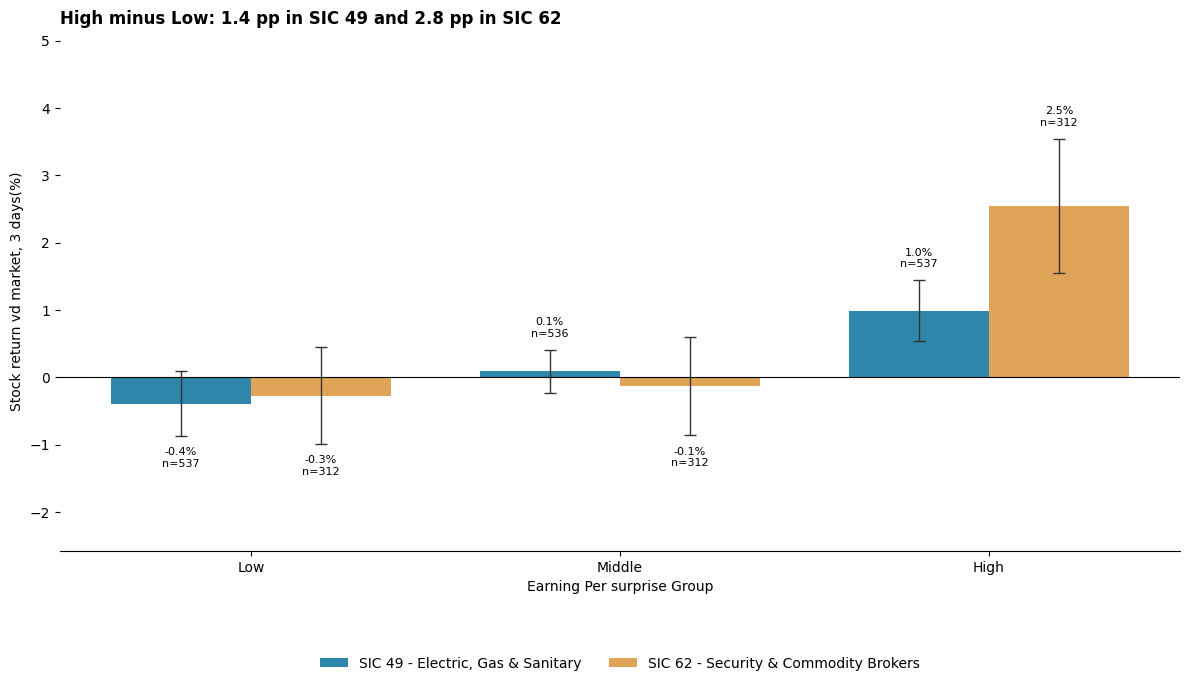

In [30]:

# ===== Figure 1: SIC 49 vs SIC 62 =====
# Project 3 - Industry Comparison

import numpy as np
import matplotlib.pyplot as plt

LABELS = ["Low", "Middle", "High"]

# ===== 1. SIC 49 group table =====

table = events.groupby("sue_group", observed=True)["car"].agg(
    n="count", mean="mean", sd="std"
).reindex(LABELS)

table["se"] = table["sd"] / np.sqrt(table["n"])
table["ci95"] = 1.96 * table["se"]

print("SIC 49")
print((table[["mean", "ci95"]] * 100).round(2).assign(n=table["n"]))


# ===== 2. SIC 62 group table =====



table_peer = events_peer.groupby(
    "sue_group", observed=True
)["car"].agg(
    n="count", mean="mean", sd="std"
).reindex(LABELS)

table_peer["se"] = table_peer["sd"] / np.sqrt(table_peer["n"])
table_peer["ci95"] = 1.96 * table_peer["se"]

print("SIC 62")
print((table_peer[["mean", "ci95"]] * 100).round(2).assign(n=table_peer["n"]))


# ===== 3. Convert CAR to percentage =====

mean = table["mean"] * 100
ci = table["ci95"] * 100

mean_peer = table_peer["mean"] * 100
ci_peer = table_peer["ci95"] * 100


# ===== 4. Create comparison chart =====

x = np.arange(len(LABELS))

# CHANGED: Professor uses width 0.38
width = 0.38

# CHANGED: Wider figure to fit annotations
fig, ax = plt.subplots(figsize=(12, 7))


# ===== 5. SIC 49 bars =====

bars49 = ax.bar(
    x - width/2,
    mean,
    width=width,
    yerr=ci,
    capsize=4,
    color="#2E86AB",
    label="SIC 49 - Electric, Gas & Sanitary",
    error_kw={
        "elinewidth": 1,
        "ecolor": "#333333"
    }
)


# ===== 6. SIC 62 bars =====

bars62 = ax.bar(
    x + width/2,
    mean_peer,
    width=width,
    yerr=ci_peer,
    capsize=4,
    color="#E0A458",  # CHANGED: Professor's peer color
    label="SIC 62 - Security & Commodity Brokers",
    error_kw={
        "elinewidth": 1,
        "ecolor": "#333333"
    }
)


# ===== 7. CAR and sample size labels =====
# CHANGED: Place labels beyond the 95% CI
# to avoid overlap with the zero line

for bars, means, cis, counts in [
    (bars49, mean, ci, table["n"]),
    (bars62, mean_peer, ci_peer, table_peer["n"])
]:
    for i, bar in enumerate(bars):

        value = means.iloc[i]
        error = cis.iloc[i]

        if value >= 0:
            label_y = value + error
            offset = 8
            alignment = "bottom"
        else:
            label_y = value - error
            offset = -8
            alignment = "top"

        ax.annotate(
            f"{value:.1f}%\nn={counts.iloc[i]:.0f}",
            xy=(
                bar.get_x() + bar.get_width()/2,
                label_y
            ),
            xytext=(0, offset),
            textcoords="offset points",
            ha="center",
            va=alignment,
            fontsize=8
        )


# ===== 8. Zero reference line =====
# SAME AS PROFESSOR

ax.axhline(
    0,
    color="black",
    linewidth=0.8
)


# ===== 9. High minus Low difference =====

spread = mean["High"] - mean["Low"]
spread_peer = mean_peer["High"] - mean_peer["Low"]

# CHANGED: Two-line title like professor's chart
title = (
    f"High minus Low: {spread:.1f} pp in SIC 49 "
    f"and {spread_peer:.1f} pp in SIC 62"
)

ax.set_title(
    title,
    loc="left",
    fontweight="bold"
)


# ===== 10. Axis labels =====

ax.set_xlabel("Earning Per surprise Group")

# Project 3 uses 3-day CAR, not 12-month returns
ax.set_ylabel("Stock return vd market, 3 days(%)")

ax.set_xticks(x)
ax.set_xticklabels(LABELS)


# ===== 11. Legend =====

# CHANGED: Professor places legend below chart
ax.legend(
    frameon=False,
    ncol=2,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18)
)


# ===== 12. Clean chart design =====

# ADDED: Hide unnecessary chart borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

# CHANGED: Leave room for labels
ax.margins(y=0.35)


# ===== 13. Save and display =====

plt.tight_layout()

fig.savefig(
    "figure1_groups.png",
    dpi=200,
    bbox_inches="tight"  # ADDED: Include legend in image
)

plt.show()


<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Analysis Figure 2</h2>

In [31]:

#1.T test

from scipy import stats

high = events.loc[events["sue_group"] == "High", "car"]
low = events.loc[events["sue_group"] == "Low", "car"]

t, p = stats.ttest_ind(high, low, equal_var=False)

print("SIC 49 Mean difference (%):", round((high.mean() - low.mean()) * 100, 2))
print("SIC 49 t-statistic:", round(t, 3))
print("SIC 49 p-value:", round(p, 4))

# Step 2: T-test for SIC 62 (Peer)

high_peer = events_peer.loc[events_peer["sue_group"] == "High", "car"]
low_peer = events_peer.loc[events_peer["sue_group"] == "Low", "car"]

t_peer, p_peer = stats.ttest_ind(high_peer, low_peer, equal_var=False)

print("SIC 62 Mean difference (%):", round((high_peer.mean() - low_peer.mean()) * 100, 2))
print("SIC 62 t-statistic:", round(t_peer, 3))
print("SIC 62 p-value:", round(p_peer, 4))

SIC 49 Mean difference (%): 1.38
SIC 49 t-statistic: 4.105
SIC 49 p-value: 0.0
SIC 62 Mean difference (%): 2.82
SIC 62 t-statistic: 4.5
SIC 62 p-value: 0.0


<h2 style="background:#1f3a5f; color:white; padding:8px 14px; border-radius:4px">Analysis Figure 2.1</h2>

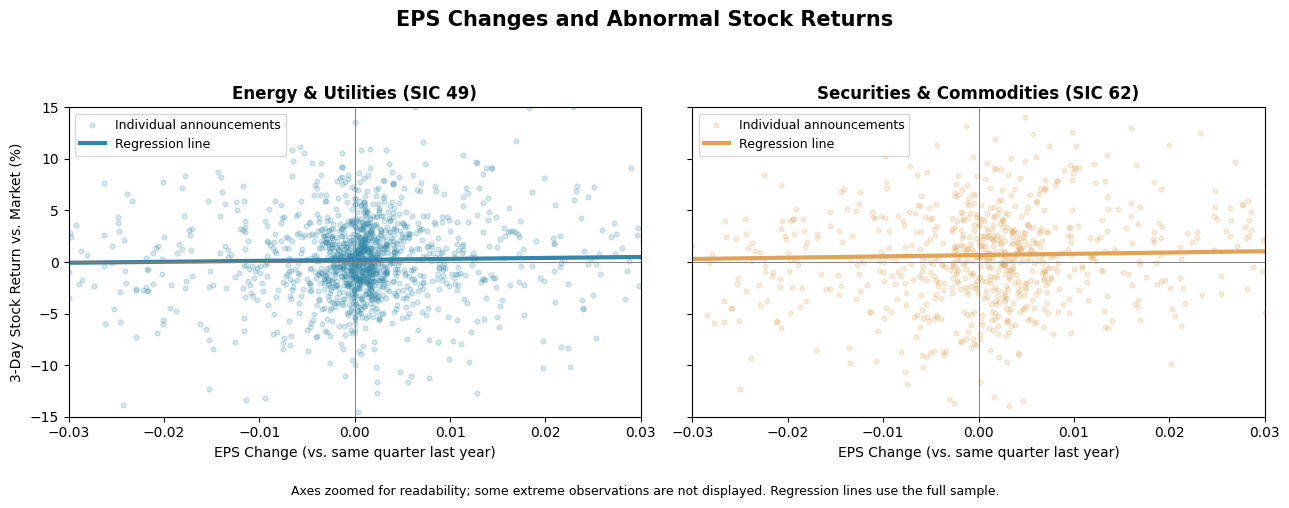

In [32]:
# Figure2 :
#2.scatter plot

import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# Regression using all announcements
model49 = smf.ols("car ~ eps_chg", data=events).fit()
model62 = smf.ols("car ~ eps_chg", data=events_peer).fit()

# Two scatterplots side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

industries = [
    (events, model49, "Energy & Utilities (SIC 49)", "#3288A8"),
    (events_peer, model62, "Securities & Commodities (SIC 62)", "#E0A458")
]

for ax, (data, model, title, color) in zip(axes, industries):

    # Each dot represents one earnings announcement
    ax.scatter(
        data["eps_chg"],
        data["car"] * 100,
        color=color,
        alpha=0.20,
        s=12,
        label="Individual announcements"
    )

    # Regression line calculated using ALL observations
    x = np.linspace(-0.03, 0.03, 100)

    ax.plot(
        x,
        model.predict({"eps_chg": x}) * 100,
        color=color,
        linewidth=3,
        label="Regression line"
    )

    # Zoom for readability
    ax.set_xlim(-0.03, 0.03)
    ax.set_ylim(-15, 15)

    ax.axhline(0, color="gray", linewidth=0.7)
    ax.axvline(0, color="gray", linewidth=0.7)

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("EPS Change (vs. same quarter last year)")
    ax.legend(loc="upper left", fontsize=9)

axes[0].set_ylabel("3-Day Stock Return vs. Market (%)")

fig.suptitle(
    "EPS Changes and Abnormal Stock Returns",
    fontsize=15,
    fontweight="bold"
)

fig.text(
    0.5, 0.01,
    "Axes zoomed for readability; some extreme observations are not displayed. "
    "Regression lines use the full sample.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 0.93])

plt.savefig("figure2_scatter_simple.png", dpi=300, bbox_inches="tight")
plt.show()

In [33]:
print("SIC 49")
print(events[["eps_chg", "car"]].describe())

print("\nSIC 62")
print(events_peer[["eps_chg", "car"]].describe())

SIC 49
           eps_chg          car
count  1610.000000  1610.000000
mean      0.002090     0.002294
std       0.069133     0.050402
min      -0.952743    -0.381414
25%      -0.002868    -0.021240
50%       0.000703     0.001491
75%       0.004686     0.025478
max       0.774428     0.374529

SIC 62
          eps_chg         car
count  936.000000  936.000000
mean     0.003330    0.007140
std      0.090683    0.075310
min     -0.979068   -0.760934
25%     -0.006504   -0.025948
50%      0.001507    0.004609
75%      0.008426    0.035225
max      0.780675    1.160469


In [34]:
# step 3 : Regression 

# sic -49
import statsmodels.api as sm

X = sm.add_constant(events["eps_chg"])
y = events["car"]

model = sm.OLS(y, X).fit()

print("SIC 49 - Electric, Gas & Sanitary Services",model.summary())


#sic-62

# step 3 : Regression 


X_peer = sm.add_constant(events_peer["eps_chg"])
y_peer = events_peer["car"]

model_peer = sm.OLS(y_peer, X_peer).fit()

print("SIC 62 - Security & Commodity Brokers",model_peer.summary())


SIC 49 - Electric, Gas & Sanitary Services                             OLS Regression Results                            
Dep. Variable:                    car   R-squared:                       0.017
Model:                            OLS   Adj. R-squared:                  0.016
Method:                 Least Squares   F-statistic:                     27.09
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           2.20e-07
Time:                        14:12:27   Log-Likelihood:                 2539.7
No. Observations:                1610   AIC:                            -5075.
Df Residuals:                    1608   BIC:                            -5065.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const    

In [35]:
# Use the actual quarterly EPS column name
eps_col = "eps_chg"

for df in [events, events_peer]:
    df["loss_group"] = np.where(
        df[eps_col] < 0,
        "Negative EPS",
        "Non-negative EPS"
    )
print("SIC 49")
print(events["loss_group"].value_counts())

print("\nSIC 62")
print(events_peer["loss_group"].value_counts())

SIC 49
loss_group
Non-negative EPS    950
Negative EPS        660
Name: count, dtype: int64

SIC 62
loss_group
Non-negative EPS    534
Negative EPS        402
Name: count, dtype: int64


SIC 49: 40.99 %
SIC 62: 42.95 %


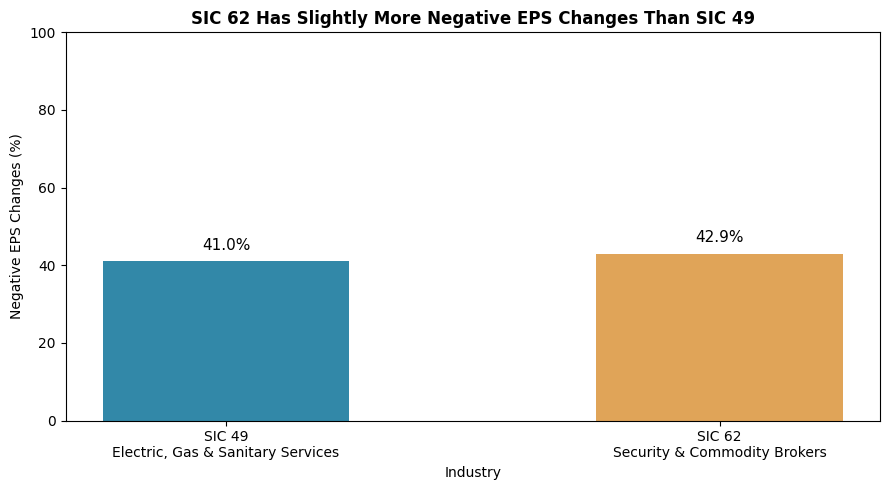

In [36]:
# ===== Figure 3: Negative EPS Change by Industry =====

import numpy as np
import matplotlib.pyplot as plt

# SIC 49
negative49 = (events["eps_chg"] < 0).mean() * 100

# SIC 62
negative62 = (events_peer["eps_chg"] < 0).mean() * 100

print("SIC 49:", round(negative49, 2), "%")
print("SIC 62:", round(negative62, 2), "%")

# Create bar graph
industries = [
    "SIC 49\nElectric, Gas & Sanitary Services",
    "SIC 62\nSecurity & Commodity Brokers"
]

percentages = [negative49, negative62]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    industries,
    percentages,
    color=["#3288A8", "#E0A458"],
    width=0.5
)

# Show percentages above bars
for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"{height:.1f}%",
        (bar.get_x() + bar.get_width()/2, height),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_title(
    "SIC 62 Has Slightly More Negative EPS Changes Than SIC 49",
    fontweight="bold"
)

ax.set_xlabel("Industry")
ax.set_ylabel("Negative EPS Changes (%)")
ax.set_ylim(0, 100)

plt.tight_layout()
fig.savefig("figure3_industry.png", dpi=200)
plt.show()

In [37]:
# ===== Compare CAR Volatility =====

print("SIC 49 CAR standard deviation (%):",
      events["car"].std() * 100)

print("SIC 62 CAR standard deviation (%):",
      events_peer["car"].std() * 100)

SIC 49 CAR standard deviation (%): 5.040235171997441
SIC 62 CAR standard deviation (%): 7.530976709926142


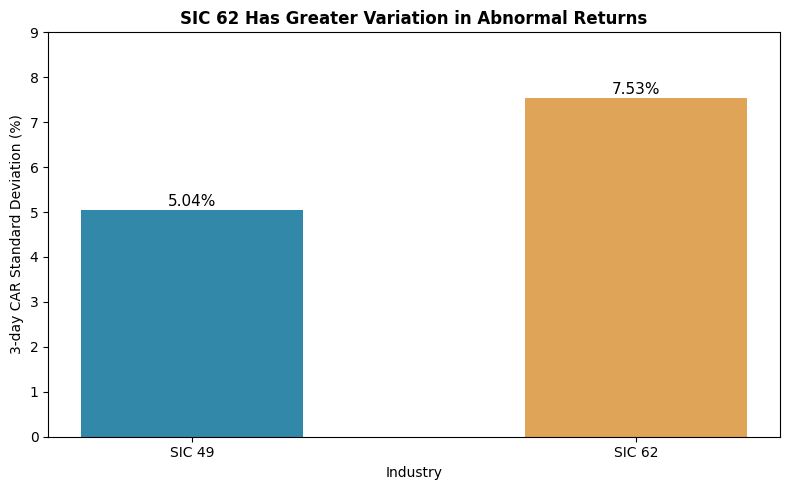

In [38]:
# ===== Figure 3: Compare CAR Volatility =====

import matplotlib.pyplot as plt

vol49 = events["car"].std() * 100
vol62 = events_peer["car"].std() * 100

industries = ["SIC 49", "SIC 62"]
volatility = [vol49, vol62]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    industries, volatility,
    color=["#3288A8", "#E0A458"],
    width=0.5
)

for i, value in enumerate(volatility):
    ax.text(i, value + 0.1, f"{value:.2f}%",
            ha="center", fontsize=11)

ax.set_title(
    "SIC 62 Has Greater Variation in Abnormal Returns",
    fontweight="bold"
)

ax.set_xlabel("Industry")
ax.set_ylabel("3-day CAR Standard Deviation (%)")
ax.set_ylim(0, 9)

plt.tight_layout()
fig.savefig("figure3_volatility.png", dpi=200)
plt.show()

In [39]:
# SIC 49 - quarterly averages
print("SIC 49")
print(events.groupby(["fyearq", "fyqr"])[["eps_chg", "car"]].mean())

# SIC 62 - quarterly averages
print("\nSIC 62")
print(events_peer.groupby(["fyearq", "fqtr"])[["eps_chg", "car"]].mean())

SIC 49
               eps_chg       car
fyearq fyqr                     
2020   20203 -0.086268 -0.005779
       20204  0.003282 -0.008935
2021   20211  0.015321  0.004024
       20212  0.002021  0.000853
       20213 -0.001874 -0.008255
       20214 -0.011642  0.008014
2022   20221  0.002170  0.013657
       20222 -0.004358  0.006049
       20223 -0.004412  0.000677
       20224  0.002168 -0.003484
2023   20231 -0.007061  0.001896
       20232  0.009561 -0.005776
       20233  0.014866  0.006266
       20234 -0.000666 -0.007193
2024   20241  0.017523  0.009294
       20242  0.004931  0.015762
       20243 -0.005843  0.003661
       20244 -0.020005  0.008119

SIC 62
              eps_chg       car
fyearq fqtr                    
2020   3     0.010587  0.030170
       4     0.053609  0.047428
2021   1     0.045329 -0.003139
       2     0.020483  0.024439
       3     0.019079  0.003587
       4    -0.015495 -0.000257
2022   1    -0.022832  0.000118
       2    -0.018227  0.015339
     

### Figure 3: Why might the industries differ?

Figure 3 shows that, for sic-49 the negative EPS changes is 41.0% of earnings announcements and for SIC 62 is 42.9%.
So SIC-62 had slightly more negative EPS changes, though it doesnot mean that the stock market reaction is down for SIC-62, because it's  High SUE group showed a stronger average stock-market reaction (+2.55%) than SIC 49 (+0.99%) ,also the differenct betwwn low and high group also shows bigger number than sic-49.

This concludes that the frequency of negative earnings changes alone does not explain the difference in market reactions.



In [40]:
# Number of announcements per quarter

print("SIC 49")
print(events.groupby("fyqr").size())

print("\nSIC 62")
print(events_peer.groupby(["fyearq", "fqtr"]).size())

SIC 49
fyqr
20203      2
20204     97
20211    104
20212    104
20213    102
20214    101
20221    101
20222    102
20223    100
20224    100
20231    100
20232    101
20233     99
20234     99
20241    100
20242     98
20243     94
20244      6
dtype: int64

SIC 62
fyearq  fqtr
2020    3        3
        4       52
2021    1       59
        2       61
        3       63
        4       59
2022    1       59
        2       62
        3       60
        4       57
2023    1       58
        2       58
        3       58
        4       57
2024    1       56
        2       56
        3       53
        4        5
dtype: int64


In [41]:
# ===== SIC 49 vs SIC 62: Final Comparison =====

from scipy import stats
import statsmodels.formula.api as smf

# ===== Step 1: SIC 49 =====

# High and Low SUE
high = events.loc[events["sue_group"] == "High", "car"]
low = events.loc[events["sue_group"] == "Low", "car"]

# T-test
t, p = stats.ttest_ind(high, low, equal_var=False)

# Regression
model = smf.ols("car ~ eps_chg", data=events).fit()


# ===== Step 2: SIC 62 =====

# High and Low SUE
high_peer = events_peer.loc[events_peer["sue_group"] == "High", "car"]
low_peer = events_peer.loc[events_peer["sue_group"] == "Low", "car"]

# T-test
t_peer, p_peer = stats.ttest_ind(
    high_peer, low_peer, equal_var=False
)

# Regression
model_peer = smf.ols("car ~ eps_chg", data=events_peer).fit()


# ===== Step 3: Final Comparison Table =====

comparison = pd.DataFrame({
    "Industry": ["SIC 49", "SIC 62"],

    "Announcements": [
        len(events),
        len(events_peer)
    ],

    "High SUE CAR (%)": [
        high.mean() * 100,
        high_peer.mean() * 100
    ],

    "Low SUE CAR (%)": [
        low.mean() * 100,
        low_peer.mean() * 100
    ],

    "High-Low Difference (pp)": [
        (high.mean() - low.mean()) * 100,
        (high_peer.mean() - low_peer.mean()) * 100
    ],

    "T-test p-value": [
        p,
        p_peer
    ],

    "Regression b": [
        model.params["eps_chg"],
        model_peer.params["eps_chg"]
    ],

    "Regression p-value": [
        model.pvalues["eps_chg"],
        model_peer.pvalues["eps_chg"]
    ],

    "R-squared": [
        model.rsquared,
        model_peer.rsquared
    ]
})


# Display final comparison
print("===== SIC 49 vs SIC 62: Final Comparison =====")
print(comparison.to_string(index=False))

===== SIC 49 vs SIC 62: Final Comparison =====
Industry  Announcements  High SUE CAR (%)  Low SUE CAR (%)  High-Low Difference (pp)  T-test p-value  Regression b  Regression p-value  R-squared
  SIC 49           1610          0.991205        -0.392010                  1.383215        0.000043      0.093837        2.195586e-07   0.016566
  SIC 62            936          2.546191        -0.272345                  2.818536        0.000008      0.125604        3.355647e-06   0.022875


Duke Energy announcements: 16


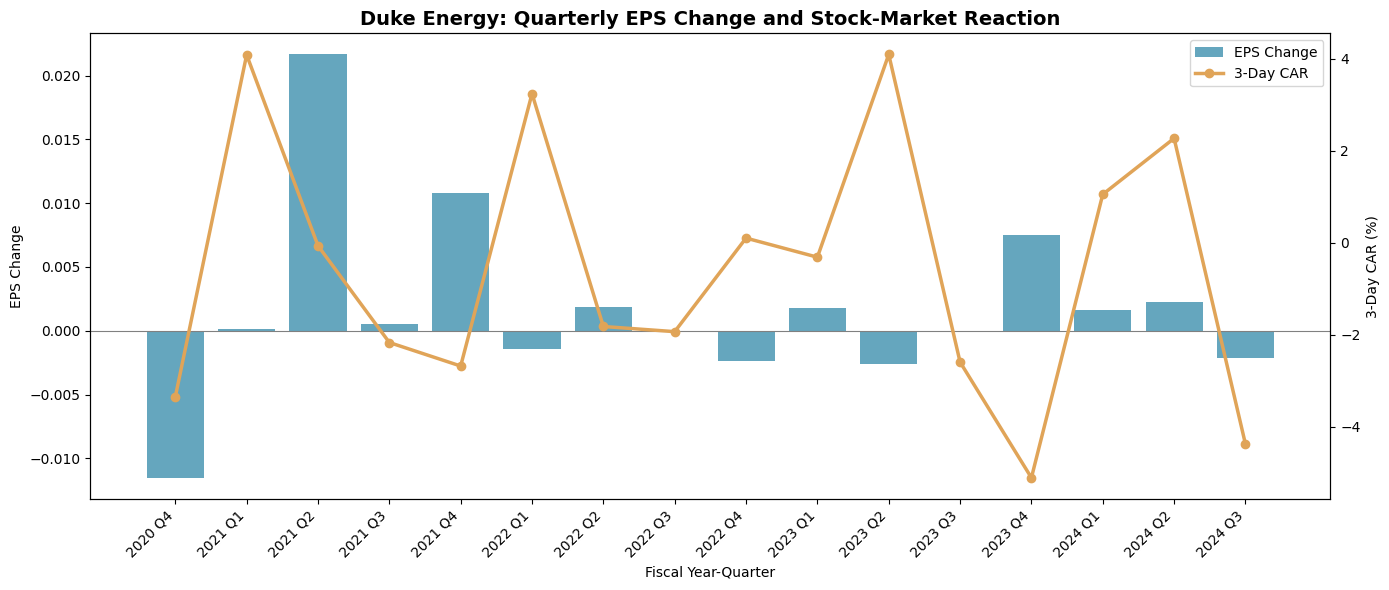

        eps_chg       car
fyqr                     
20204 -0.011518 -0.033521
20211  0.000109  0.040862
20212  0.021651 -0.000651
20213  0.000506 -0.021687
20214  0.010759 -0.026801
20221 -0.001430  0.032417
20222  0.001881 -0.018206
20223 -0.000093 -0.019329
20224 -0.002365  0.001018
20231  0.001748 -0.003136
20232 -0.002591  0.040940
20233  0.000000 -0.025940
20234  0.007478 -0.051099
20241  0.001649  0.010527
20242  0.002275  0.022711
20243 -0.002095 -0.043783


In [42]:
import matplotlib.pyplot as plt

# ===== Duke Energy: Quarterly EPS Change vs CAR =====

# Step 1: Select Duke Energy from SIC 49
if "ticker" in events.columns:
    duke = events[events["ticker"].astype(str).str.upper() == "DUK"].copy()

elif "conm" in events.columns:
    duke = events[
        events["conm"].astype(str).str.contains(
            "DUKE ENERGY", case=False, na=False
        )
    ].copy()

else:
    raise ValueError(
        "Duke's ticker or company name is not available. "
        "Check events.columns and identify Duke's gvkey."
    )

print("Duke Energy announcements:", len(duke))

if duke.empty:
    raise ValueError("No Duke Energy observations found. Check the company identifier.")

# Step 2: Quarterly data
if "fyqr" in duke.columns:
    qduke = duke.groupby("fyqr")[["eps_chg", "car"]].mean().sort_index()

else:
    qduke = duke.groupby(
        ["fyearq", "fqtr"]
    )[["eps_chg", "car"]].mean().sort_index()

# Step 3: Create readable quarter labels
if isinstance(qduke.index, __import__("pandas").MultiIndex):
    labels = [
        str(year) + " Q" + str(quarter)
        for year, quarter in qduke.index
    ]
else:
    labels = [
        str(q)[:4] + " Q" + str(q)[-1]
        for q in qduke.index
    ]

# Step 4: Create chart
fig, ax = plt.subplots(figsize=(14, 6))

x = range(len(qduke))

# Blue bars = EPS Change
ax.bar(
    x, qduke["eps_chg"],
    color="#3288A8",
    alpha=0.75,
    label="EPS Change"
)

ax.set_ylabel("EPS Change")
ax.set_xticks(list(x))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.axhline(0, color="gray", linewidth=0.8)

# Orange line = 3-day CAR
ax2 = ax.twinx()

ax2.plot(
    x, qduke["car"] * 100,
    color="#E0A458",
    marker="o",
    linewidth=2.5,
    label="3-Day CAR"
)

ax2.set_ylabel("3-Day CAR (%)")

# Title
ax.set_title(
    "Duke Energy: Quarterly EPS Change and Stock-Market Reaction",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Fiscal Year-Quarter")

# Combined legend
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper right"
)

plt.tight_layout()
plt.show()

# Step 5: Print actual Duke quarterly results
print(qduke)

DUKE ENERGY
       eps_chg     car
count   16.000  16.000
mean     0.002  -0.006
std      0.007   0.029
min     -0.012  -0.051
25%     -0.002  -0.026
50%      0.000  -0.011
75%      0.002   0.014
max      0.022   0.041
Duke rows changed by winsorizing: 2 of 16

SIC 49 INDUSTRY
        eps_chg       car
count  1610.000  1610.000
mean      0.002     0.002
std       0.069     0.050
min      -0.953    -0.381
25%      -0.003    -0.021
50%       0.001     0.001
75%       0.005     0.025
max       0.774     0.375
SIC 49 rows changed by winsorizing: 34 of 1610

===== DUKE: ORIGINAL =====
                            OLS Regression Results                            
Dep. Variable:                    car   R-squared:                       0.003
Model:                            OLS   Adj. R-squared:                 -0.068
Method:                 Least Squares   F-statistic:                   0.04214
Date:                Mon, 23 Nov 2026   Prob (F-statistic):              0.840
Time:             

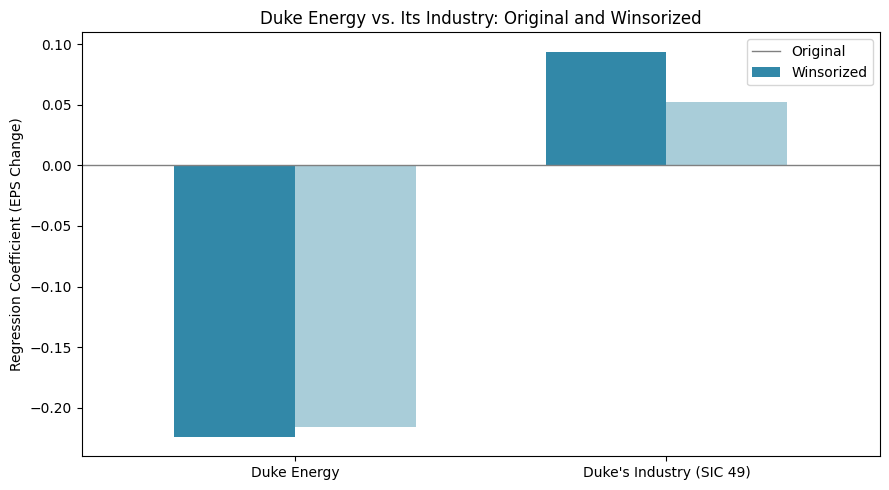

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# ===== 4a. Look at extremes, then winsorize CAR at 1% and 99% =====

# Duke Energy
duke = duke.dropna(subset=["eps_chg", "car"]).copy()

print("DUKE ENERGY")
print(duke[["eps_chg", "car"]].describe().round(3))

lo, hi = duke["car"].quantile([0.01, 0.99])
duke["car_w"] = duke["car"].clip(lo, hi)

print("Duke rows changed by winsorizing:",
      (duke["car"] != duke["car_w"]).sum(), "of", len(duke))


# Duke's industry (SIC 49)
print("\nSIC 49 INDUSTRY")
print(events[["eps_chg", "car"]].describe().round(3))

lo, hi = events["car"].quantile([0.01, 0.99])
events["car_w"] = events["car"].clip(lo, hi)

print("SIC 49 rows changed by winsorizing:",
      (events["car"] != events["car_w"]).sum(), "of", len(events))


# ===== 4b. Regression: original and winsorized =====

# Duke Energy
model_duke = smf.ols("car ~ eps_chg", data=duke).fit()
model_duke_w = smf.ols("car_w ~ eps_chg", data=duke).fit()

# SIC 49
model_49 = smf.ols("car ~ eps_chg", data=events).fit()
model_49_w = smf.ols("car_w ~ eps_chg", data=events).fit()


# ===== 4c. Full regression results =====

print("\n===== DUKE: ORIGINAL =====")
print(model_duke.summary())

print("\n===== DUKE: WINSORIZED =====")
print(model_duke_w.summary())

print("\n===== SIC 49: ORIGINAL =====")
print(model_49.summary())

print("\n===== SIC 49: WINSORIZED =====")
print(model_49_w.summary())


# ===== 4d. Compare results =====

results = pd.DataFrame({
    "b (slope)": [
        model_duke.params["eps_chg"],
        model_duke_w.params["eps_chg"],
        model_49.params["eps_chg"],
        model_49_w.params["eps_chg"]
    ],
    "p-value of b": [
        model_duke.pvalues["eps_chg"],
        model_duke_w.pvalues["eps_chg"],
        model_49.pvalues["eps_chg"],
        model_49_w.pvalues["eps_chg"]
    ],
    "R-squared": [
        model_duke.rsquared,
        model_duke_w.rsquared,
        model_49.rsquared,
        model_49_w.rsquared
    ],
    "n": [
        int(model_duke.nobs),
        int(model_duke_w.nobs),
        int(model_49.nobs),
        int(model_49_w.nobs)
    ]
}, index=[
    "Duke - Original",
    "Duke - Winsorized",
    "SIC 49 - Original",
    "SIC 49 - Winsorized"
]).round(4)

print("\n===== REGRESSION COMPARISON =====")
print(results)


# ===== 4e. Bar chart =====

chart = pd.DataFrame({
    "Original": [
        model_duke.params["eps_chg"],
        model_49.params["eps_chg"]
    ],
    "Winsorized": [
        model_duke_w.params["eps_chg"],
        model_49_w.params["eps_chg"]
    ]
}, index=["Duke Energy", "Duke's Industry (SIC 49)"])

ax = chart.plot(
    kind="bar",
    figsize=(9, 5),
    color=["#3288A8", "#A9CDD9"],
    width=0.65
)

plt.axhline(0, color="gray", linewidth=1)
plt.title("Duke Energy vs. Its Industry: Original and Winsorized")
plt.ylabel("Regression Coefficient (EPS Change)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.legend(["Original", "Winsorized"])
plt.tight_layout()
plt.show()

* 5 days abnormal reurn******

In [44]:

# ===== Step 5. Calculate 11-day CAR (Day -5 to Day +5) =====
# Adapted from the class notebook


# ===== SIC 49: Energy & Utilities =====

# 5a. Give every company-quarter a unique event_id
# Remove old event-window columns if the cell was run before
events_abn = events_abn.drop(
    columns=["event_id", "day0", "car_11", "days_found_11"],
    errors="ignore"
).reset_index(drop=True)

events_abn["event_id"] = events_abn.index

print("SIC 49 events:", len(events_abn))

# 5b. Match announcements with market trading dates
pairs_abn = events_abn[["event_id", "rdq"]].merge(
    mkt[["date", "tday"]],
    how="cross"
)

print("After Merge pair:", len(pairs_abn))

# 5c. Convert dates
pairs_abn["rdq"] = pd.to_datetime(pairs_abn["rdq"])
pairs_abn["date"] = pd.to_datetime(pairs_abn["date"])

pairs_abn = pairs_abn[
    pairs_abn["date"] >= pairs_abn["rdq"]
]

# 5d. Find first trading day on or after earnings date
day0_abn = pairs_abn.groupby("event_id")["tday"].min().reset_index()
day0_abn = day0_abn.rename(columns={"tday": "day0"})

events_abn = events_abn.merge(
    day0_abn,
    on="event_id",
    how="left",
    validate="one_to_one"
)

# 5e. Create Day -5 through Day +5
offsets_abn = pd.DataFrame({
    "offset_days": range(-5, 6)
})

window_abn = events_abn[
    ["event_id", "permno", "rdq", "day0"]
].merge(
    offsets_abn,
    how="cross"
)

window_abn["tday"] = (
    window_abn["day0"] + window_abn["offset_days"]
)

print("11-day window rows:", len(window_abn))

# 5f. Match daily abnormal returns
window_abn = window_abn.merge(
    stock[["permno", "tday", "ar"]],
    on=["permno", "tday"],
    how="left",
    validate="many_to_one"
)

# 5g. Sum returns and count available days
abn_5 = window_abn.groupby("event_id")["ar"].agg(
    ["sum", "count"]
).reset_index()

abn_5 = abn_5.rename(columns={
    "sum": "car_11",
    "count": "days_found_11"
})

# 5h. Add 11-day CAR to events
events_abn = events_abn.merge(
    abn_5,
    on="event_id",
    how="left",
    validate="one_to_one"
)

events_abn["days_found_11"] = (
    events_abn["days_found_11"].fillna(0).astype(int)
)

print("\nSIC 49: Trading days found")
print(events_abn["days_found_11"].value_counts().sort_index())

# Incomplete windows are not valid 11-day CAR
events_abn.loc[
    events_abn["days_found_11"] != 11, "car_11"
] = float("nan")

# 5i. Check the window
print(window_abn[
    ["event_id", "rdq", "offset_days", "tday", "ar"]
].head(11))

r9, c9 = (
    events_abn["car_11"].count(),
    events_abn.loc[
        events_abn["car_11"].notna(), "gvkey"
    ].nunique()
)

print("SIC 49 complete 11-day CAR:", r9)


# ===== SIC 62: Securities & Commodities =====

# 5a. Give every company-quarter a unique event_id
events_peer_abn = events_peer_abn.drop(
    columns=["event_id", "day0", "car_11", "days_found_11"],
    errors="ignore"
).reset_index(drop=True)

events_peer_abn["event_id"] = events_peer_abn.index

print("\nSIC 62 events:", len(events_peer_abn))

# 5b. Match announcements with trading dates
pairs_peer_abn = events_peer_abn[
    ["event_id", "rdq"]
].merge(
    mkt[["date", "tday"]],
    how="cross"
)

print("After Merge pair:", len(pairs_peer_abn))

# 5c. Convert dates
pairs_peer_abn["rdq"] = pd.to_datetime(pairs_peer_abn["rdq"])
pairs_peer_abn["date"] = pd.to_datetime(pairs_peer_abn["date"])

pairs_peer_abn = pairs_peer_abn[
    pairs_peer_abn["date"] >= pairs_peer_abn["rdq"]
]

# 5d. Find first trading day
day0_peer_abn = pairs_peer_abn.groupby(
    "event_id"
)["tday"].min().reset_index()

day0_peer_abn = day0_peer_abn.rename(
    columns={"tday": "day0"}
)

events_peer_abn = events_peer_abn.merge(
    day0_peer_abn,
    on="event_id",
    how="left",
    validate="one_to_one"
)

# 5e. Create Day -5 through Day +5
offsets_peer_abn = pd.DataFrame({
    "offset_days": range(-5, 6)
})

window_peer_abn = events_peer_abn[
    ["event_id", "permno", "rdq", "day0"]
].merge(
    offsets_peer_abn,
    how="cross"
)

window_peer_abn["tday"] = (
    window_peer_abn["day0"] + window_peer_abn["offset_days"]
)

print("11-day window rows:", len(window_peer_abn))

# 5f. Match abnormal stock returns
window_peer_abn = window_peer_abn.merge(
    stock_peer[["permno", "tday", "ar"]],
    on=["permno", "tday"],
    how="left",
    validate="many_to_one"
)

# 5g. Sum returns and count days
abn_peer_5 = window_peer_abn.groupby(
    "event_id"
)["ar"].agg(
    ["sum", "count"]
).reset_index()

abn_peer_5 = abn_peer_5.rename(columns={
    "sum": "car_11",
    "count": "days_found_11"
})

# 5h. Add 11-day CAR
events_peer_abn = events_peer_abn.merge(
    abn_peer_5,
    on="event_id",
    how="left",
    validate="one_to_one"
)

events_peer_abn["days_found_11"] = (
    events_peer_abn["days_found_11"].fillna(0).astype(int)
)

print("\nSIC 62: Trading days found")
print(
    events_peer_abn["days_found_11"]
    .value_counts().sort_index()
)

# Incomplete windows are not valid 11-day CAR
events_peer_abn.loc[
    events_peer_abn["days_found_11"] != 11, "car_11"
] = float("nan")

# 5i. Check the window
print(window_peer_abn[
    ["event_id", "rdq", "offset_days", "tday", "ar"]
].head(11))

r9_peer, c9_peer = (
    events_peer_abn["car_11"].count(),
    events_peer_abn.loc[
        events_peer_abn["car_11"].notna(), "gvkey"
    ].nunique()
)

print("SIC 62 complete 11-day CAR:", r9_peer)


# ===== Final summary =====

print("\n===== 11-DAY CAR SUMMARY =====")
print("SIC 49:", r9, "announcements,", c9, "companies")
print("SIC 62:", r9_peer, "announcements,", c9_peer, "companies")

print("\nAverage 11-day CAR (%)")
print("SIC 49:", round(events_abn["car_11"].mean() * 100, 3))
print("SIC 62:", round(events_peer_abn["car_11"].mean() * 100, 3))


SIC 49 events: 1618
After Merge pair: 1661686
11-day window rows: 17798

SIC 49: Trading days found
days_found_11
0        5
6        3
10       2
11    1608
Name: count, dtype: int64
    event_id         rdq  offset_days  tday        ar
0          0  2021-02-24           -5    53  0.017209
1          0  2021-02-24           -4    54  0.006844
2          0  2021-02-24           -3    55 -0.014516
3          0  2021-02-24           -2    56 -0.012253
4          0  2021-02-24           -1    57  0.013482
5          0  2021-02-24            0    58 -0.043616
6          0  2021-02-24            1    59  0.026335
7          0  2021-02-24            2    60 -0.038733
8          0  2021-02-24            3    61  0.009126
9          0  2021-02-24            4    62  0.028657
10         0  2021-02-24            5    63  0.004759
SIC 49 complete 11-day CAR: 1608

SIC 62 events: 953
After Merge pair: 978731
11-day window rows: 10483

SIC 62: Trading days found
days_found_11
0      17
7       2
11

In [45]:
events_abn = events_abn[
    events_abn["days_found_11"] == 11
].copy()

events_peer_abn = events_peer_abn[
    events_peer_abn["days_found_11"] == 11
].copy()

print("SIC 49:", len(events_abn))
print("SIC 62:", len(events_peer_abn))

SIC 49: 1608
SIC 62: 934


SIC 49 matched announcements: 1608
SIC 62 matched announcements: 934

===== 3-DAY VS. 11-DAY REGRESSION =====
  Industry   Window  Coefficient  P-value  R-squared (%)     N
0   SIC 49   3 days       0.0937   0.0000         1.6527  1608
1   SIC 49  11 days       0.1096   0.0000         1.0509  1608
2   SIC 62   3 days       0.1265   0.0000         2.3093   934
3   SIC 62  11 days       0.0681   0.0421         0.4423   934


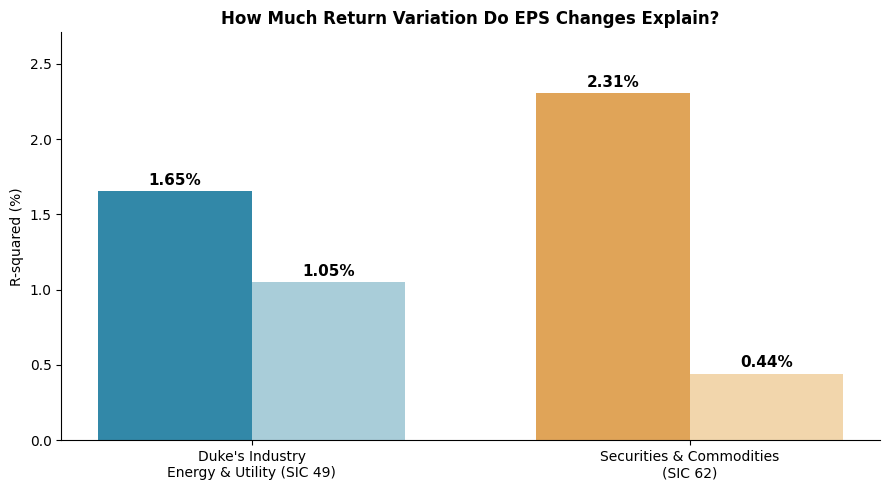

In [46]:
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# ===== 1. Match the same announcements =====
# Use company and quarter identifiers rather than event_id,
# because event_id was assigned separately in each dataset.

keys = ["gvkey", "fyearq", "fqtr"]

data49 = events[keys + ["eps_chg", "car"]].merge(
    events_abn[keys + ["car_11"]],
    on=keys,
    how="inner",
    validate="one_to_one"
).dropna()

data62 = events_peer[keys + ["eps_chg", "car"]].merge(
    events_peer_abn[keys + ["car_11"]],
    on=keys,
    how="inner",
    validate="one_to_one"
).dropna()

print("SIC 49 matched announcements:", len(data49))
print("SIC 62 matched announcements:", len(data62))


# ===== 2. Run regressions =====

# SIC 49
model49_3 = smf.ols("car ~ eps_chg", data=data49).fit()
model49_11 = smf.ols("car_11 ~ eps_chg", data=data49).fit()

# SIC 62
model62_3 = smf.ols("car ~ eps_chg", data=data62).fit()
model62_11 = smf.ols("car_11 ~ eps_chg", data=data62).fit()


# ===== 3. Create comparison table =====

results = pd.DataFrame({
    "Industry": ["SIC 49", "SIC 49", "SIC 62", "SIC 62"],
    "Window": ["3 days", "11 days", "3 days", "11 days"],
    "Coefficient": [
        model49_3.params["eps_chg"],
        model49_11.params["eps_chg"],
        model62_3.params["eps_chg"],
        model62_11.params["eps_chg"]
    ],
    "P-value": [
        model49_3.pvalues["eps_chg"],
        model49_11.pvalues["eps_chg"],
        model62_3.pvalues["eps_chg"],
        model62_11.pvalues["eps_chg"]
    ],
    "R-squared (%)": [
        model49_3.rsquared * 100,
        model49_11.rsquared * 100,
        model62_3.rsquared * 100,
        model62_11.rsquared * 100
    ],
    "N": [
        int(model49_3.nobs),
        int(model49_11.nobs),
        int(model62_3.nobs),
        int(model62_11.nobs)
    ]
})

print("\n===== 3-DAY VS. 11-DAY REGRESSION =====")
print(results.round(4))


# ===== 4. Plot R-squared comparison =====
# ===== 4. Plot R-squared comparison =====
# Same industry colors as previous figures
# Dark = 3 days, Light = 11 days

import numpy as np
import matplotlib.pyplot as plt

industries = ["SIC 49", "SIC 62"]

# Get R-squared values from the results table
r3 = results[results["Window"] == "3 days"]["R-squared (%)"].values
r11 = results[results["Window"] == "11 days"]["R-squared (%)"].values

x = np.arange(len(industries))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

# SIC 49 - Blue
ax.bar(
    x[0] - width/2, r3[0], width,
    color="#3288A8"
)
ax.bar(
    x[0] + width/2, r11[0], width,
    color="#A9CDD9"
)

# SIC 62 - Orange
ax.bar(
    x[1] - width/2, r3[1], width,
    color="#E0A458"
)
ax.bar(
    x[1] + width/2, r11[1], width,
    color="#F2D6AC"
)

# Add value labels
for bar in ax.patches:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.04,
        f"{height:.2f}%",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_xticks(x)
ax.set_xticklabels([
    "Duke's Industry\nEnergy & Utility (SIC 49)",
    "Securities & Commodities\n(SIC 62)"
])

ax.set_ylabel("R-squared (%)")
ax.set_title(
    "How Much Return Variation Do EPS Changes Explain?",
    fontweight="bold"
)

# Legend explaining darker and lighter colors
from matplotlib.patches import Patch



ax.set_ylim(0, max(r3.max(), r11.max()) + 0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("figure_3day_vs_11day.png", dpi=300, bbox_inches="tight")
plt.show()

In [47]:
conn.close()